# Scikit-learn — Modelling and learning from data

Scikit-learn provides a consistent interface for regression, classification, preprocessing, and unsupervised learning. The package is installed as `scikit-learn` and imported as `sklearn`.

This tutorial follows the accompanying notebooks: brief explanations, small executable examples, scientific interpretation, and exercises. It assumes Python, NumPy, Matplotlib, and basic descriptive statistics. Familiarity with Pandas is helpful.

Execute cells in order. Synthetic data and the bundled Iris dataset make every example available offline. The objective is a correct modelling workflow, rather than a catalogue of algorithms. Worked solutions appear at the end.

## Contents

1. Setup and estimator interface
2. Regression and held-out evaluation
3. Classification and performance metrics
4. Preprocessing and Pipelines
5. Cross-validation and model selection
6. Mixed data and missing values
7. Clustering and principal components
8. Exercises and worked solutions

## Setup — run this first

Use fixed random seeds to make the teaching examples reproducible. Results can still vary slightly between library versions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay)
from sklearn.datasets import load_iris, make_blobs
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

plt.rcParams.update({'figure.figsize': (8,4), 'font.size': 11})
print('Scikit-learn:', sklearn.__version__)

Scikit-learn: 1.8.0


## Samples, features, and targets

The feature matrix has shape `(n_samples, n_features)`. Rows are observations; columns are measured predictors. The target `y` contains the quantity or class to predict.

In [2]:
X_small = np.array([[1.], [2.], [3.], [4.]])
y_small = np.array([3., 5., 7., 9.])
X_small.shape, y_small.shape

((4, 1), (4,))

In [3]:
model_small = LinearRegression()
model_small.fit(X_small, y_small)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## The estimator interface

`fit` estimates model parameters. `predict` applies the fitted model. Learned attributes conventionally end in an underscore.

In [4]:
model_small.coef_, model_small.intercept_

(array([2.]), np.float64(1.0))

In [5]:
model_small.predict([[2.5], [5.]])

array([ 6., 11.])

In [6]:
model_small.get_params()

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}

A one-feature dataset must still be two-dimensional. `reshape(-1, 1)` converts a vector of observations into a single feature column. Predicting outside the observed range is extrapolation and needs separate physical justification.

## Regression: a synthetic calibration

Consider the linear relation $U=RI+b+\epsilon$. Current is the predictor; voltage is the target. Independent Gaussian noise represents measurement scatter. This example assumes current uncertainty is negligible.

In [7]:
reg_rng = np.random.default_rng(12)
current_A = np.linspace(.01, .50, 120)
voltage_V = 12.0*current_A + .15 + reg_rng.normal(0, .15, current_A.size)
X_reg = current_A.reshape(-1,1)
y_reg = voltage_V
X_reg.shape, y_reg.shape

((120, 1), (120,))

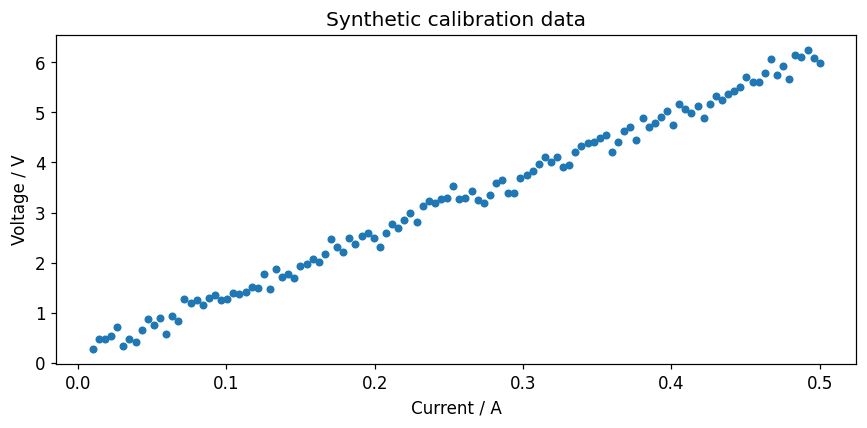

In [8]:
fig, ax = plt.subplots()
ax.scatter(current_A, voltage_V, s=18)
ax.set(xlabel='Current / A', ylabel='Voltage / V', title='Synthetic calibration data')
plt.tight_layout(); plt.show()

## Split before fitting

Training data determine the parameters. Test data estimate performance on observations withheld from fitting. A random split is appropriate here because the noise is independent; chronological or grouped data require another strategy.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=.25, random_state=42)
X_train.shape, X_test.shape

((90, 1), (30, 1))

In [10]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print(f'Estimated resistance: {regressor.coef_[0]:.3f} Ω')
print(f'Estimated offset: {regressor.intercept_:.3f} V')

Estimated resistance: 12.041 Ω
Estimated offset: 0.147 V


In [11]:
y_pred = regressor.predict(X_test)
y_pred[:5]

array([2.4490423 , 2.59778326, 0.46582954, 2.99442581, 1.55659656])

## Regression metrics

MAE measures typical absolute error. RMSE penalises large errors more strongly. Both retain the target units. $R^2=1-\sum(y-\hat y)^2/\sum(y-\bar y)^2$ compares against the test-set mean and can be negative.

In [12]:
regression_metrics = pd.Series({
    'MAE_V': mean_absolute_error(y_test,y_pred),
    'RMSE_V': np.sqrt(mean_squared_error(y_test,y_pred)),
    'R2': r2_score(y_test,y_pred),
})
regression_metrics

MAE_V     0.118348
RMSE_V    0.149763
R2        0.991883
dtype: float64

In [13]:
baseline_reg = DummyRegressor(strategy='mean').fit(X_train,y_train)
print('Baseline RMSE / V:', np.sqrt(mean_squared_error(y_test,baseline_reg.predict(X_test))))

Baseline RMSE / V: 1.691789538139674


## Inspecting residuals

Residuals are observed minus predicted values. A good aggregate score can conceal systematic structure.

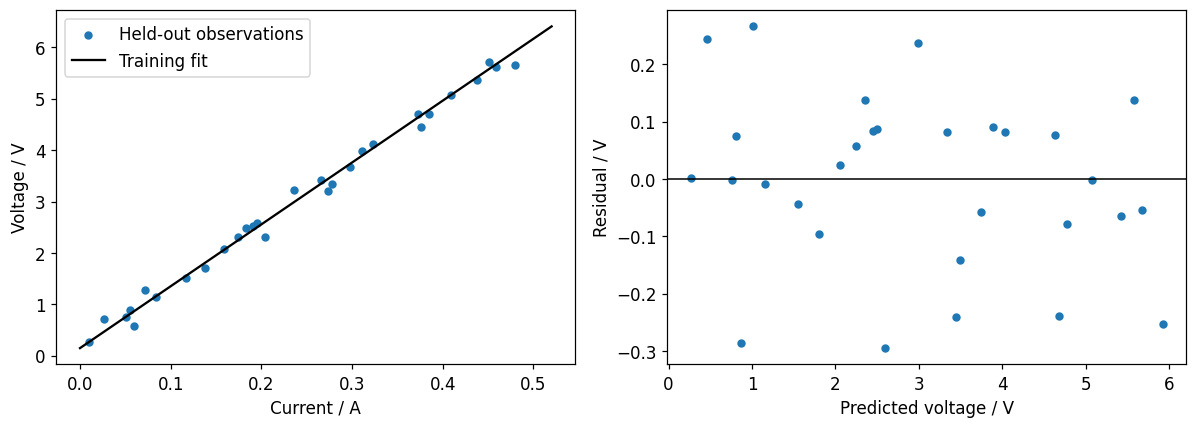

In [14]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
xx = np.linspace(0,.52,150).reshape(-1,1)
axes[0].scatter(X_test[:,0],y_test,label='Held-out observations',s=20)
axes[0].plot(xx[:,0],regressor.predict(xx),color='black',label='Training fit')
axes[0].set(xlabel='Current / A',ylabel='Voltage / V'); axes[0].legend()
axes[1].scatter(y_pred,y_test-y_pred,s=20)
axes[1].axhline(0,color='black',lw=1)
axes[1].set(xlabel='Predicted voltage / V',ylabel='Residual / V')
plt.tight_layout(); plt.show()

## Exercise I: Linear calibration

Use the existing training split to estimate resistance and offset. Predict voltage at 0.25 A. Calculate test MAE by hand with NumPy and compare it with scikit-learn. Does high predictive accuracy establish the physical model?

Try the task before consulting the worked solutions at the end.

In [15]:
# calibration_model = LinearRegression().fit(...)
# prediction_at_025 = ...
# manual_mae = ...

## Underfitting and overfitting

A model can reproduce training noise and generalise poorly. Compare restricted and flexible models using internal validation; reserve a final test set for the selected procedure.

In [16]:
curve_rng = np.random.default_rng(29)
X_curve = np.linspace(-2,2,100).reshape(-1,1)
y_curve = np.sin(2*X_curve[:,0]) + curve_rng.normal(0,.18,100)
X_curve_train,X_curve_valid,y_curve_train,y_curve_valid = train_test_split(
    X_curve,y_curve,test_size=.3,random_state=10)
curve_results=[]
for depth in [1,3,None]:
    tree=DecisionTreeRegressor(max_depth=depth,random_state=42).fit(X_curve_train,y_curve_train)
    curve_results.append({'max_depth':str(depth),
        'train_RMSE':np.sqrt(mean_squared_error(y_curve_train,tree.predict(X_curve_train))),
        'validation_RMSE':np.sqrt(mean_squared_error(y_curve_valid,tree.predict(X_curve_valid)))})
pd.DataFrame(curve_results)

,max_depth,train_RMSE,validation_RMSE
0,1,0.546735,0.581248
1,3,0.218590,0.292172
2,None,0.000000,0.279508


## Polynomial regression and regularisation

Polynomial features expand the predictors. Ridge regression penalises large coefficients through $\|y-X\beta\|^2+\alpha\|\beta\|^2$. Scaling and the penalty are part of the fitted procedure. The intercept is fitted separately and is not penalised.

In [17]:
poly_model = make_pipeline(PolynomialFeatures(degree=5,include_bias=False),
                           StandardScaler(),Ridge(alpha=1.0))
poly_model.fit(X_curve_train,y_curve_train)
print('Validation RMSE:', np.sqrt(mean_squared_error(y_curve_valid,poly_model.predict(X_curve_valid))))

Validation RMSE: 0.26920907573232994


## Exercise II: Model flexibility

Compare polynomial degrees 1, 3, and 8 on the same training and validation split. Use scaling and Ridge in a Pipeline. Report both RMSE values. Explain why training error alone cannot select the degree.

Try the task before consulting the worked solutions at the end.

In [18]:
# Loop over degrees and collect training/validation errors.

## Classification: the Iris dataset

Classification predicts a discrete label. Iris contains 150 observations, four measured flower dimensions, and three species. It is bundled with scikit-learn and requires no download.

In [19]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target
X_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [20]:
iris.target_names, y_iris.value_counts().sort_index()

(array(['setosa', 'versicolor', 'virginica'], dtype='<U10'), target
0    50
1    50
2    50
Name: count, dtype: int64)

In [21]:
Xi_train,Xi_test,yi_train,yi_test = train_test_split(
    X_iris,y_iris,test_size=.25,random_state=42,stratify=y_iris)
print('Training:', Xi_train.shape, 'Test:', Xi_test.shape)

Training: (112, 4) Test: (38, 4)


## Transformers and scaling

`StandardScaler` estimates a mean and standard deviation from training observations. `transform` applies those same estimates to new observations. Never fit the scaler on the test set.

In [22]:
scaler = StandardScaler().fit(Xi_train)
Xi_train_scaled = scaler.transform(Xi_train)
Xi_test_scaled = scaler.transform(Xi_test)
Xi_train_scaled.mean(axis=0), Xi_train_scaled.std(axis=0)

(array([9.35759406e-16, 4.75809868e-17, 2.61695427e-16, 1.70498536e-16]), array([1., 1., 1., 1.]))

## A Pipeline combines transformations and estimation

A Pipeline ensures that the same transformations precede every prediction. During cross-validation, its preprocessing is fitted separately inside each training fold.

In [23]:
classifier = Pipeline([
    ('scale',StandardScaler()),
    ('model',LogisticRegression(max_iter=2000)),
])
classifier.fit(Xi_train,yi_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not wor

In [24]:
iris_predictions = classifier.predict(Xi_test)
print('Test accuracy:', accuracy_score(yi_test,iris_predictions))

Test accuracy: 0.9210526315789473


In [25]:
probabilities = classifier.predict_proba(Xi_test)
probabilities[:3], probabilities.sum(axis=1)[:3]

(array([[9.84578820e-01, 1.54208114e-02, 3.68658391e-07],
       [3.36139381e-02, 6.21376673e-01, 3.45009389e-01],
       [4.50856559e-02, 8.82484250e-01, 7.24300942e-02]]), array([1., 1., 1.]))

The probability columns follow `classifier.classes_`. Probability estimates are model outputs; their calibration requires assessment. Accuracy on this small dataset is not a guarantee of performance on a new population.

## Baselines and confusion matrices

Compare against a simple baseline. The confusion matrix records true classes by row and predicted classes by column.

In [26]:
baseline_cls = DummyClassifier(strategy='most_frequent').fit(Xi_train,yi_train)
print('Baseline accuracy:',accuracy_score(yi_test,baseline_cls.predict(Xi_test)))
print(classification_report(yi_test,iris_predictions,target_names=iris.target_names,zero_division=0))

Baseline accuracy: 0.3157894736842105
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



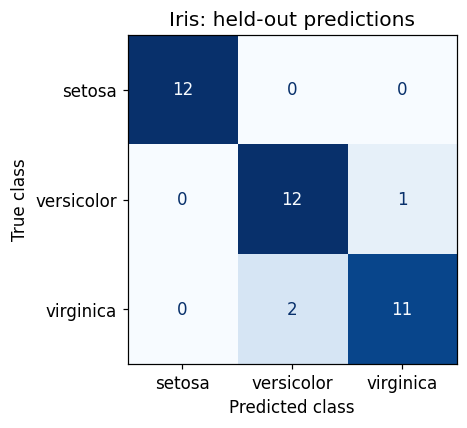

In [27]:
disp = ConfusionMatrixDisplay.from_predictions(yi_test,iris_predictions,
    labels=[0,1,2],display_labels=iris.target_names,cmap='Blues',colorbar=False)
disp.ax_.set(xlabel='Predicted class',ylabel='True class',title='Iris: held-out predictions')
plt.tight_layout(); plt.show()

## Accuracy under class imbalance

Accuracy can hide failure on a minority class. Balanced accuracy averages class recall. Precision and recall answer different questions and should be interpreted in context.

In [28]:
y_imbalanced = np.array([0]*95 + [1]*5)
y_all_zero = np.zeros(100,dtype=int)
print('Accuracy:',accuracy_score(y_imbalanced,y_all_zero))
print('Balanced accuracy:',balanced_accuracy_score(y_imbalanced,y_all_zero))

Accuracy: 0.95
Balanced accuracy: 0.5


## Exercise III: A second classifier

Fit a scaled five-neighbour classifier on the Iris training set. Evaluate it once on the existing test set and inspect its confusion matrix. Explain why repeatedly choosing models by this test score invalidates its role as a final assessment.

Try the task before consulting the worked solutions at the end.

In [29]:
# knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
# Fit and evaluate.

## Cross-validation

Cross-validation repeats training and validation within the training data. Stratification approximately preserves class proportions. Report variability across folds rather than only the highest score.

In [30]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_scores = cross_val_score(classifier,Xi_train,yi_train,cv=cv,scoring='accuracy',n_jobs=1)
print('Fold scores:',cv_scores)
print(f'Mean ± fold standard deviation: {cv_scores.mean():.3f} ± {cv_scores.std(ddof=1):.3f}')

Fold scores: [1.         0.86956522 1.         0.95454545 1.        ]
Mean ± fold standard deviation: 0.965 ± 0.057


The fold standard deviation describes this resampling result; it is not automatically a confidence interval. For repeated subjects use group-aware splitting. For forecasting use chronological splitting, such as `TimeSeriesSplit`, and avoid future information.

## Hyperparameter search

A hyperparameter specifies the learning procedure before fitting. `GridSearchCV` compares candidates using training-only cross-validation and refits the selected candidate on all supplied training data.

In [31]:
search = GridSearchCV(
    Pipeline([('scale',StandardScaler()),('model',KNeighborsClassifier())]),
    param_grid={'model__n_neighbors':[3,5,9,15]},cv=cv,scoring='accuracy',n_jobs=1)
search.fit(Xi_train,yi_train)
search.best_params_, search.best_score_

({'model__n_neighbors': 3}, np.float64(0.9731225296442687))

In [32]:
pd.DataFrame(search.cv_results_)[['param_model__n_neighbors','mean_test_score','std_test_score','rank_test_score']]

,param_model__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,3,0.973123,0.021957,1
1,5,0.964427,0.032761,2
2,9,0.955731,0.047638,4
3,15,0.964427,0.032761,2


`best_score_` is a model-selection score, not an unbiased final performance estimate. In a new study, evaluate the chosen procedure once on an untouched test set, or use nested cross-validation. The Iris test set above has already served demonstration comparisons.

## Exercise IV: Tune without test leakage

Search the Ridge penalty for the polynomial regression example using five-fold cross-validation on its training portion. Use negative mean squared error as the score. Convert the selected mean score to a root-mean-square scale and explain the sign.

Try the task before consulting the worked solutions at the end.

In [33]:
# search_reg = GridSearchCV(...)
# Fit using X_curve_train and y_curve_train only.

## Mixed data and missing values

Scientific tables often combine numerical measurements and instrument labels. Use a ColumnTransformer to apply different preprocessing to each column group. Imputation, scaling, and category encoding belong inside the Pipeline.

In [34]:
mixed_rng=np.random.default_rng(8)
instruments=mixed_rng.choice(['A','B','C'],size=180)
mixed_current=mixed_rng.uniform(.02,.5,180)
X_mixed=pd.DataFrame({'current_A':mixed_current,
                     'temperature_C':mixed_rng.normal(20,2,180),
                     'instrument':instruments})
y_mixed=(10*mixed_current+.03*(X_mixed['temperature_C'].to_numpy()-20)
         +np.where(instruments=='B',.2,0)+mixed_rng.normal(0,.08,180))
X_mixed.loc[::13,'temperature_C']=np.nan
Xm_train,Xm_test,ym_train,ym_test=train_test_split(X_mixed,y_mixed,test_size=.25,random_state=42)
Xm_train.head()

,current_A,temperature_C,instrument
132,0.373514,19.313087,C
90,0.269516,16.777300,B
38,0.345704,21.532428,B
169,0.396045,NaN,C
115,0.352309,21.976926,B


In [35]:
numeric_preprocessing=make_pipeline(SimpleImputer(strategy='median'),StandardScaler())
categorical_preprocessing=make_pipeline(SimpleImputer(strategy='most_frequent'),
                                       OneHotEncoder(handle_unknown='ignore'))
preprocessing=ColumnTransformer([
    ('numeric',numeric_preprocessing,['current_A','temperature_C']),
    ('category',categorical_preprocessing,['instrument']),
])
mixed_model=make_pipeline(preprocessing,Ridge(alpha=1.))
mixed_model.fit(Xm_train,ym_train)
print('Mixed-data test RMSE / V:',np.sqrt(mean_squared_error(ym_test,mixed_model.predict(Xm_test))))

Mixed-data test RMSE / V: 0.08951880408880952


In [36]:
mixed_model.named_steps['columntransformer'].get_feature_names_out()

array(['numeric__current_A', 'numeric__temperature_C',
       'category__instrument_A', 'category__instrument_B',
       'category__instrument_C'], dtype=object)

Unknown categories are encoded without raising an error because `handle_unknown="ignore"` was specified. This behaviour does not establish that a prediction for a new instrument is physically reliable. Evaluate such deployment conditions separately.

## Exercise V: Predict from a measurement table

Create a two-row DataFrame with the same predictor columns. Include one missing temperature and one previously unseen instrument label. Predict using the fitted mixed-data Pipeline. Explain which training estimates are reused.

Try the task before consulting the worked solutions at the end.

In [37]:
# new_measurements = pd.DataFrame(...)
# mixed_model.predict(new_measurements)

## Unsupervised learning: clustering

Clustering groups observations without target labels. K-means minimises within-cluster squared Euclidean distance. Its geometry is sensitive to scale, outliers, and the specified number of clusters.

In [38]:
X_blobs,_ = make_blobs(n_samples=240,centers=3,cluster_std=.75,random_state=42)
cluster_model=make_pipeline(StandardScaler(),KMeans(n_clusters=3,n_init=10,random_state=42))
cluster_labels=cluster_model.fit_predict(X_blobs)
np.bincount(cluster_labels)

array([80, 80, 80])

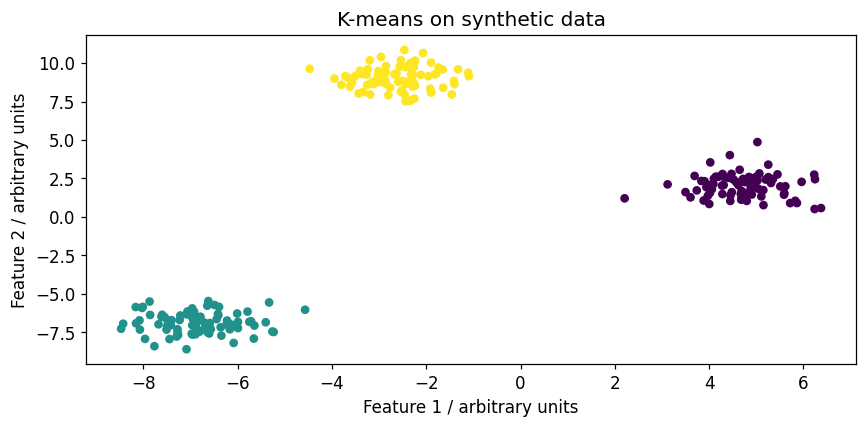

In [39]:
fig,ax=plt.subplots()
ax.scatter(X_blobs[:,0],X_blobs[:,1],c=cluster_labels,cmap='viridis',s=22)
ax.set(xlabel='Feature 1 / arbitrary units',ylabel='Feature 2 / arbitrary units',title='K-means on synthetic data')
plt.tight_layout();plt.show()

Cluster labels such as 0, 1, and 2 have no intrinsic ordering or physical identity. Separated clusters in a demonstration do not prove that a measured dataset contains distinct physical populations.

## Principal component analysis

PCA finds orthogonal directions of largest variance. It is a linear projection, not a classifier. Standardise first when feature units or scales differ.

In [40]:
pca_model=make_pipeline(StandardScaler(),PCA(n_components=2))
# Fit on training observations; project test observations using the same transformation.
Z_train=pca_model.fit_transform(Xi_train)
Z_test=pca_model.transform(Xi_test)
pca_model.named_steps['pca'].explained_variance_ratio_

array([0.73911238, 0.22125712])

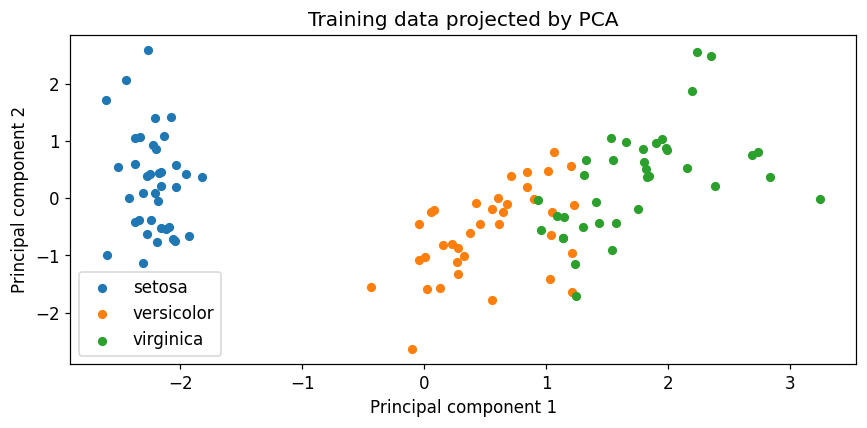

In [41]:
fig,ax=plt.subplots()
for label,name in enumerate(iris.target_names):
    selected=yi_train.to_numpy()==label
    ax.scatter(Z_train[selected,0],Z_train[selected,1],label=name,s=25)
ax.set(xlabel='Principal component 1',ylabel='Principal component 2',title='Training data projected by PCA')
ax.legend();plt.tight_layout();plt.show()

Species labels colour the plot but are not supplied to PCA. The explained variance ratio quantifies retained variance, not classification accuracy. High-variance directions need not be the most useful predictors.

## Exercise VI: Projection and interpretation

Fit PCA with two and three components after scaling, using the Iris training data only. Report cumulative explained variance. Explain why this does not measure predictive performance.

Try the task before consulting the worked solutions at the end.

In [42]:
# For each component count, fit a scaler/PCA pipeline and sum explained_variance_ratio_.

## A final independent evaluation

The earlier examples illustrate individual tools. This final example uses a fresh dataset and a complete split–select–evaluate procedure. Hyperparameter selection sees only training folds.

In [43]:
final_rng=np.random.default_rng(2026)
X_final=final_rng.uniform(-2,2,(180,1))
y_final=np.sin(2*X_final[:,0])+final_rng.normal(0,.15,180)
Xf_train,Xf_test,yf_train,yf_test=train_test_split(X_final,y_final,test_size=.25,random_state=7)
final_search=GridSearchCV(
    make_pipeline(PolynomialFeatures(include_bias=False),StandardScaler(),Ridge()),
    {'polynomialfeatures__degree':[1,3,5,7], 'ridge__alpha':[.01,.1,1.]},
    cv=KFold(5,shuffle=True,random_state=7),scoring='neg_mean_squared_error',n_jobs=1)
final_search.fit(Xf_train,yf_train)
final_predictions=final_search.predict(Xf_test)
print('Selected parameters:',final_search.best_params_)
print('Final held-out RMSE:',np.sqrt(mean_squared_error(yf_test,final_predictions)))
# Do not return to tuning after inspecting this final test result.

Selected parameters: {'polynomialfeatures__degree': 7, 'ridge__alpha': 0.01}
Final held-out RMSE: 0.15781893604209463


## Common mistakes

Split before fitting transformations. Keep preprocessing inside cross-validation. Compare with a baseline and inspect residuals or class errors. Match the splitting method to time and group structure. A predictive score alone does not establish causation, parameter uncertainty, or validity beyond the sampled domain.

# Worked solutions

These examples are intended for comparison after an independent attempt. Each solution creates its own working variables and leaves the tutorial data unchanged.

## Solution I: Linear calibration

In [44]:
calibration_solution = LinearRegression().fit(X_train,y_train)
prediction_solution = calibration_solution.predict([[.25]])[0]
manual_mae_solution = np.mean(np.abs(y_test-calibration_solution.predict(X_test)))
print('Voltage at 0.25 A / V:', prediction_solution)
print('Manual MAE / V:', manual_mae_solution)
assert np.isclose(manual_mae_solution, mean_absolute_error(y_test,calibration_solution.predict(X_test)))
# Prediction alone does not establish causation or validate all physical assumptions.

Voltage at 0.25 A / V: 3.1573325739739007
Manual MAE / V: 0.11834759105217613


## Solution II: Model flexibility

In [45]:
degree_results=[]
for degree in [1,3,8]:
    candidate=make_pipeline(PolynomialFeatures(degree,include_bias=False),StandardScaler(),Ridge(alpha=.1))
    candidate.fit(X_curve_train,y_curve_train)
    degree_results.append({'degree':degree,
        'train_RMSE':np.sqrt(mean_squared_error(y_curve_train,candidate.predict(X_curve_train))),
        'validation_RMSE':np.sqrt(mean_squared_error(y_curve_valid,candidate.predict(X_curve_valid)))})
display(pd.DataFrame(degree_results))
# Use validation, not the smallest training error, to compare flexibility.

,degree,train_RMSE,validation_RMSE
0,1,0.662338,0.696494
1,3,0.280313,0.227062
2,8,0.226639,0.163672


## Solution III: A second classifier

In [46]:
knn_solution=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))
knn_solution.fit(Xi_train,yi_train)
knn_predictions_solution=knn_solution.predict(Xi_test)
print('KNN test accuracy:',accuracy_score(yi_test,knn_predictions_solution))
display(pd.crosstab(pd.Series(yi_test.to_numpy(),name='True'),
                    pd.Series(knn_predictions_solution,name='Predicted')))
# This comparison is pedagogical. For model selection use training-only cross-validation.

KNN test accuracy: 0.9210526315789473


Predicted,0,1,2
True,,,
0,12,0,0
1,0,13,0
2,0,3,10


## Solution IV: Tune without test leakage

In [47]:
ridge_search_solution=GridSearchCV(
    make_pipeline(PolynomialFeatures(5,include_bias=False),StandardScaler(),Ridge()),
    {'ridge__alpha':[.001,.01,.1,1.,10.]},
    cv=KFold(n_splits=5,shuffle=True,random_state=42),
    scoring='neg_mean_squared_error',n_jobs=1)
ridge_search_solution.fit(X_curve_train,y_curve_train)
print('Selected:',ridge_search_solution.best_params_)
print('Root of mean fold MSE:',np.sqrt(-ridge_search_solution.best_score_))
# Scores are maximised, so scikit-learn negates losses.
# sqrt(mean MSE) is not generally equal to the mean of fold RMSE values.

Selected: {'ridge__alpha': 0.01}
Root of mean fold MSE: 0.22906346016672813


## Solution V: Predict from a measurement table

In [48]:
new_solution=pd.DataFrame({'current_A':[.1,.3],'temperature_C':[np.nan,22.],
                           'instrument':['A','D']})
display(new_solution)
print('Predicted voltage / V:',mixed_model.predict(new_solution))
# The imputation median, scaling statistics, category vocabulary, and model coefficients are reused.

Predicted voltage / V: [1.02290928 3.13661144]


,current_A,temperature_C,instrument
0,0.1,NaN,A
1,0.3,22.0,D


## Solution VI: Projection and interpretation

In [49]:
for components in [2,3]:
    projection_solution=make_pipeline(StandardScaler(),PCA(n_components=components))
    projection_solution.fit(Xi_train)
    retained=projection_solution.named_steps['pca'].explained_variance_ratio_.sum()
    print(f'{components} components: retained variance = {retained:.3f}')
# PCA has not used targets or evaluated predictions; variance retention is a different objective.

2 components: retained variance = 0.960
3 components: retained variance = 0.996


# Documentation

- [Scikit-learn: getting started](https://scikit-learn.org/stable/getting_started.html)
- [Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)

These are original teaching examples, structured to accompany the four supplied introductory notebooks.